In [1]:
import sys
import os
import pandas as pd
import scanpy as sc
from mudata import MuData
import muon as mu
import numpy as np
from cellphonedb.utils import search_utils
import ktplotspy as kpy
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
# os.chdir('/data1/liyuzhe/Ref/cpdb')

2026-03-19 17:30:03.610559: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-19 17:30:03.668968: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-19 17:30:04.585944: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
print(sys.version)

3.8.5 (default, Sep  4 2020, 07:30:14) 
[GCC 7.3.0]


In [3]:
# figure settings
sc.settings.set_figure_params(dpi=200, frameon=False)
sc.set_figure_params(dpi=200, facecolor="white")
sc.set_figure_params(figsize=(5, 5))
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype']  = 42

# Load results

In [4]:
cts=['Group3', 'Group4', 'Lymphocyte', 'Macrophage_01_CD44',
       'Macrophage_02_FLT1', 'Macrophage_03_FYN', 'Microglia_01_P2RY12',
       'Microglia_02_DNAJB1', 'Microglia_03_IGF2R', 'Microglia_04_ITGAX',
       'Microglia_05_KLF2', 'Microglia_06_IL1B', 'Microglia_07_MKI67', 'SHH']

In [5]:
cpdb_file_path = '/data1/liyuzhe/Ref/cpdb/v4.1.0/cellphonedb.zip'
meta_file_path = 'data/metadata.tsv'
counts_file_path = 'data/normalised_log_counts.h5ad'
out_path = 'results/method2'

In [6]:
# read in the files
# 1) .h5ad file used for performing cellphonedb
adata=sc.read(counts_file_path)

# 2) output from cellphonedb
means = pd.read_csv("results/method2/statistical_analysis_means_03_19_2026_11:00:36.txt", sep="\t")
pvalues = pd.read_csv("results/method2/statistical_analysis_pvalues_03_19_2026_11:00:36.txt", sep="\t")
deconvoluted = pd.read_csv("results/method2/statistical_analysis_deconvoluted_03_19_2026_11:00:36.txt", sep="\t")
significant_means = pd.read_csv("results/method2/statistical_analysis_significant_means_03_19_2026_11:00:36.txt", sep="\t")

# Explore CellPhoneDB results

In [7]:
# search_results = search_utils.search_analysis_results(
#     query_cell_types_1 = ['Microglia','Macrophage'],  # List of cells 1, will be paired to cells 2 (list or 'All').
#     query_cell_types_2 = ['MB'],     # List of cells 2, will be paired to cells 1 (list or 'All').
#     query_genes = [],                                       # filter interactions based on the genes participating (list).
#     query_interactions = [],                            # filter intereactions based on their name (list).
#     significant_means = significant_means,                          # significant_means file generated by CellPhoneDB.
#     deconvoluted = deconvoluted,                                    # devonvoluted file generated by CellPhoneDB.
#     separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
#     long_format = True                                              # converts the output into a wide table, removing non-significant interactions
# )

In [8]:
# search_results.head(10)

In [9]:
search_results = search_utils.search_analysis_results(
    query_cell_types_1 = cts,  # List of cells 1, will be paired to cells 2 (list or 'All').
    query_cell_types_2 = cts,     # List of cells 2, will be paired to cells 1 (list or 'All').
    # query_genes = ['VEGFA'],                                       # filter interactions based on the genes participating (list).
    # query_interactions = ['VEGFA_ITGAV'],                            # filter intereactions based on their name (list).
    significant_means = significant_means,                          # significant_means file generated by CellPhoneDB.
    deconvoluted = deconvoluted,                                    # devonvoluted file generated by CellPhoneDB.
    separator = '|',                                                # separator (default: |) employed to split cells (cellA|cellB).
    long_format = True                                              # converts the output into a wide table, removing non-significant interactions
)

# Basic analysis and plotting

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored


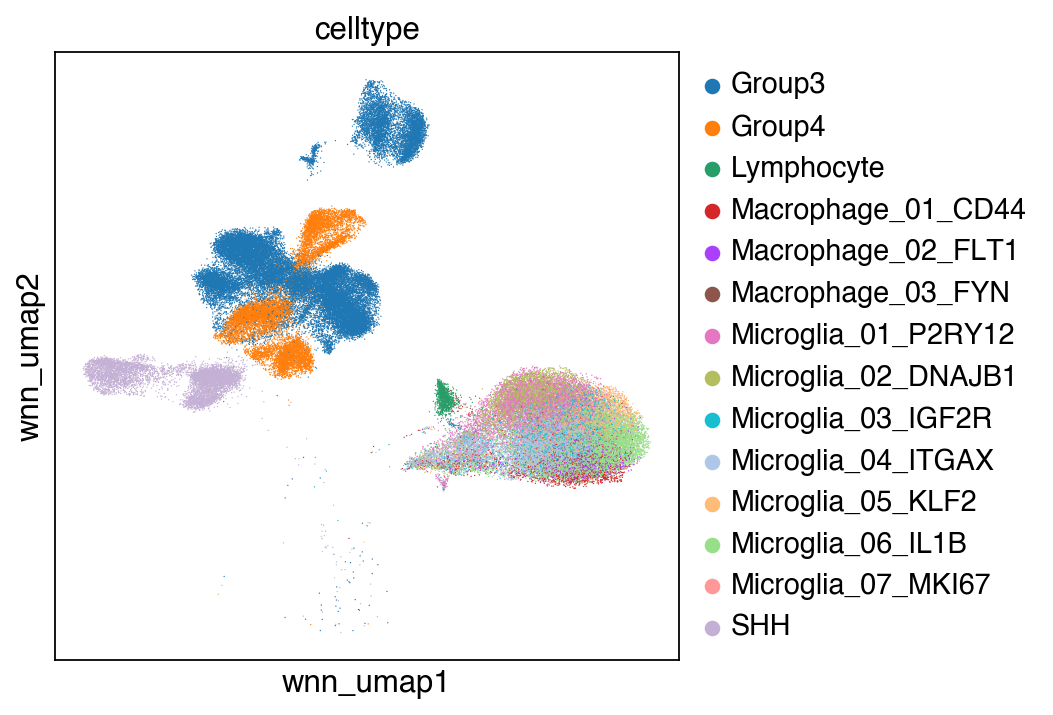

In [10]:
sc.pl.embedding(adata,basis='wnn_umap',color='celltype')

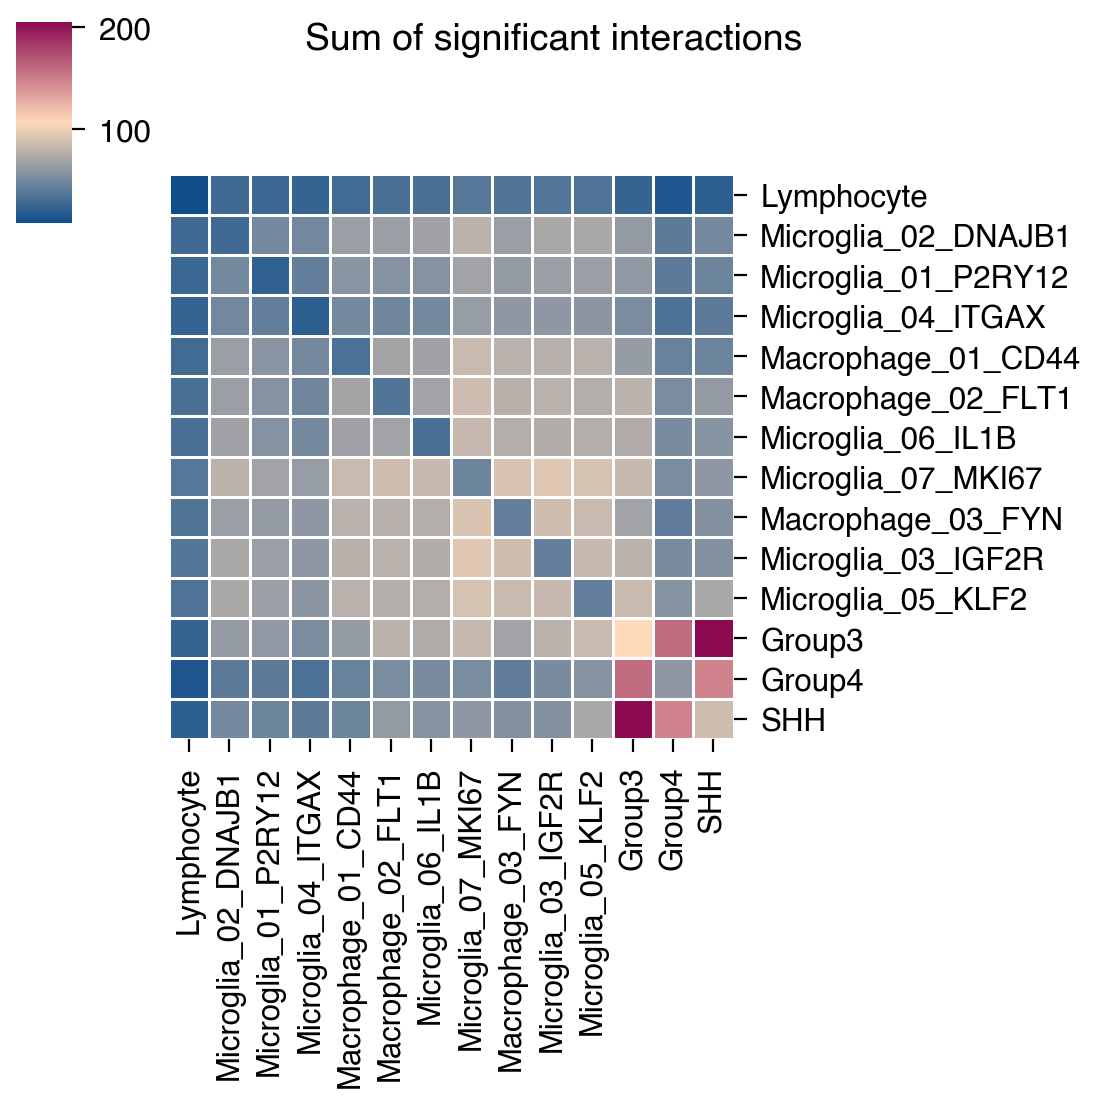

In [11]:
plt.rcParams["axes.grid"] = False
kpy.plot_cpdb_heatmap(pvals = pvalues,
                      degs_analysis = False,
                      figsize = (7, 7),
                      title = "Sum of significant interactions")

In [12]:
cts2=['Group3', 'Group4', 'SHH']
cts1=['Lymphocyte', 'Macrophage_01_CD44',
       'Macrophage_02_FLT1', 'Macrophage_03_FYN', 'Microglia_01_P2RY12',
       'Microglia_02_DNAJB1', 'Microglia_03_IGF2R', 'Microglia_04_ITGAX',
       'Microglia_05_KLF2', 'Microglia_06_IL1B', 'Microglia_07_MKI67',]

In [13]:
sl=['id_cp_interaction', 'interacting_pair', 'partner_a', 'partner_b',
    'gene_a', 'gene_b', 'secreted', 'receptor_a', 'receptor_b',
    'annotation_strategy', 'is_integrin', ]
for i in cts1:
    for j in cts2:
        sl.append(i+'|'+j)
        sl.append(j+'|'+i)
means_sub=means[sl].copy()
pvalues_sub=pvalues[sl].copy()

In [14]:
p=kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "", 
    cell_type2 = "",
    means = means_sub,
    pvals = pvalues_sub,
    alpha=0.01,
    celltype_key = "celltype",
    figsize=(20, 20),
    highlight_size=0.5,
    # standard_scale=True,
)
p.save('figures/CCI_all_MB.pdf')

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 20 x 20 in image.
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: figures/CCI_all_MB.pdf
webf NOT subset; don't know how to subset; dropped


In [16]:
sl=['id_cp_interaction', 'interacting_pair', 'partner_a', 'partner_b',
    'gene_a', 'gene_b', 'secreted', 'receptor_a', 'receptor_b',
    'annotation_strategy', 'is_integrin']
for i in cts1:
    for j in ['Group3']:
        sl.append(i+'|'+j)
        sl.append(j+'|'+i)
means_sub=means[sl].copy()
pvalues_sub=pvalues[sl].copy()

p=kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "", 
    cell_type2 = "",
    means = means_sub,
    pvals = pvalues_sub,
    celltype_key = "celltype",
    genes = ['ROR2', 'BSG', 'ERBB4', 'EGFR', 'PLXNA4', 'NRXN1', 'CD44'],
    figsize = (10,6),
    title = "",
    max_size = 6,
    highlight_size = 0.75,
    standard_scale = True
)
p.save('figures/CCI_MB_G3.pdf')

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 10 x 6 in image.
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: figures/CCI_MB_G3.pdf
webf NOT subset; don't know how to subset; dropped


In [18]:
sl=['id_cp_interaction', 'interacting_pair', 'partner_a', 'partner_b',
    'gene_a', 'gene_b', 'secreted', 'receptor_a', 'receptor_b',
    'annotation_strategy', 'is_integrin']
for i in cts1:
    for j in ['SHH']:
        sl.append(i+'|'+j)
        sl.append(j+'|'+i)
means_sub=means[sl].copy()
pvalues_sub=pvalues[sl].copy()

p=kpy.plot_cpdb(
    adata = adata,
    cell_type1 = "", 
    cell_type2 = "",
    means = means_sub,
    pvals = pvalues_sub,
    celltype_key = "celltype",
    genes = ['PLXNC1', 'IGF1R', 'ROR2'],
    figsize = (10,4),
    title = "",
    max_size = 6,
    highlight_size = 0.75,
    standard_scale = True
)
p.save('figures/CCI_MB_SHH.pdf')

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:587: PlotnineWarning: Saving 10 x 4 in image.
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/plotnine/ggplot.py:588: PlotnineWarning: Filename: figures/CCI_MB_SHH.pdf
webf NOT subset; don't know how to subset; dropped
